# Лабораторна робота: PCA, кластеризація та виявлення аномалій
**Мета:** реалізувати відтворюваний pipeline з коректним preprocessing без leakage,
діагностикою PCA, кластеризацією (KMeans) у двох просторах і детекторами аномалій.

In [1]:
import numpy as np
import pandas as pd
import json, time, hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score,
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RNG_SEED = 42

# 3.1 Директорії та контракт запуску

In [2]:
ROOT = Path("lab_pca_anomaly")
for d in ["results", "illustrations", "artifacts", "src", "tests", "configs"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT.resolve())
print("Subdirs:", [p.name for p in ROOT.iterdir()])

Project root: E:\Linux\BML\lab 5\lab_pca_anomaly
Subdirs: ['artifacts', 'configs', 'illustrations', 'results', 'src', 'tests']


# 3.3 Конфігурація + валідація


In [4]:
CONFIG = {
    "seed": 42,
    "n_samples": 600,
    "n_features": 10,
    "n_classes": 3,
    "test_frac": 0.25,
    "pca_thresholds": [0.80, 0.90, 0.95],
    "k_grid": [2, 3, 4, 5, 6, 7],
    "n_seeds": 5,
    "if_params": {"n_estimators": 200, "contamination": 0.05},
    "threshold_quantile": 0.95,
}

def validate_config(cfg):
    errs = []
    if not (0 < cfg.get("test_frac", -1) < 1):
        errs.append("test_frac має бути в (0,1)")
    if cfg.get("n_samples", 0) < 500:
        errs.append("n_samples має бути >= 500")
    if cfg.get("n_features", 0) < 10:
        errs.append("n_features має бути >= 10")
    if len(cfg.get("k_grid", [])) < 6:
        errs.append("k_grid має містити >= 6 значень")
    if cfg.get("n_seeds", 0) < 5:
        errs.append("n_seeds має бути >= 5")
    if not (0 < cfg.get("threshold_quantile", -1) < 1):
        errs.append("threshold_quantile має бути в (0,1)")
    if errs:
        raise ValueError("Невалідна конфігурація:\n - " + "\n - ".join(errs))
    return True

validate_config(CONFIG)
with open(ROOT / "configs/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
print("Config OK")

Config OK


# 3.2 Дані + стабільний split

In [6]:
def load_and_split(config):
    X, y = make_classification(
        n_samples=config["n_samples"], n_features=config["n_features"],
        n_informative=7, n_redundant=2, n_classes=config["n_classes"],
        n_clusters_per_class=1, random_state=config["seed"])
    ids = np.array([f"S{i:04d}" for i in range(len(X))])

    # стабільний hash-split за id
    h = np.array([int(hashlib.md5(f"{config['seed']}_{i}".encode()).hexdigest(), 16)
                  for i in ids])
    order = h.argsort()
    n_test = int(len(ids) * config["test_frac"])
    test_idx  = np.sort(order[:n_test])
    train_idx = np.sort(order[n_test:])

    assert set(ids[train_idx]).isdisjoint(set(ids[test_idx])), "ids перетинаються!"
    return {"X_train": X[train_idx], "X_test": X[test_idx],
            "y_train": y[train_idx], "y_test": y[test_idx],
            "ids_train": ids[train_idx], "ids_test": ids[test_idx]}

bundle = load_and_split(CONFIG)
print(f"train={len(bundle['X_train'])}, test={len(bundle['X_test'])}")
print("ids перетинаються?", not set(bundle['ids_train']).isdisjoint(set(bundle['ids_test'])))

train=450, test=150
ids перетинаються? False


# 3.4 Preprocessing без leakage

In [7]:
def fit_preprocessor(X_train, config):
    imp = SimpleImputer(strategy="median").fit(X_train)
    sc  = StandardScaler().fit(imp.transform(X_train))
    keep = sc.var_ > 1e-12   # викидаємо сталі колонки
    return {"imputer": imp, "scaler": sc, "keep": keep}

def transform(prep, X):
    Xt = prep["imputer"].transform(X)
    Xt = prep["scaler"].transform(Xt)
    return Xt[:, prep["keep"]]

prep = fit_preprocessor(bundle["X_train"], CONFIG)
X_train_s = transform(prep, bundle["X_train"])
X_test_s  = transform(prep, bundle["X_test"])
print("scaled:", X_train_s.shape, X_test_s.shape)

scaled: (450, 10) (150, 10)


Важливо. transform() для test викликає лише transform, не fit. Усі параметри (медіана, середнє, σ) оцінені на train.

# 3.5 Діагностика PCA (повна)

In [9]:
def pca_diagnostics(X_train_scaled, config):
    pca = PCA(n_components=X_train_scaled.shape[1],
              random_state=config["seed"]).fit(X_train_scaled)
    table = pd.DataFrame({
        "component": np.arange(1, len(pca.explained_variance_ratio_)+1),
        "explained_variance": pca.explained_variance_,
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_variance": np.cumsum(pca.explained_variance_ratio_),
    })
    return pca, table

pca_full, pca_table = pca_diagnostics(X_train_s, CONFIG)
pca_table.to_csv(ROOT / "results/pca_table.csv", index=False)
pca_table

,component,explained_variance,explained_variance_ratio,cumulative_variance
0,1,2.484416e+00,2.478895e-01,0.247890
1,2,2.141426e+00,2.136667e-01,0.461556
2,3,1.671456e+00,1.667742e-01,0.628330
3,4,1.287749e+00,1.284887e-01,0.756819
4,5,9.956872e-01,9.934746e-02,0.856167
5,6,7.003794e-01,6.988230e-02,0.926049
6,7,5.754615e-01,5.741827e-02,0.983467
7,8,1.656966e-01,1.653284e-02,1.000000
8,9,3.555914e-17,3.548012e-18,1.000000
9,10,0.000000e+00,0.000000e+00,1.000000


# Scree plot + кумулятивна крива

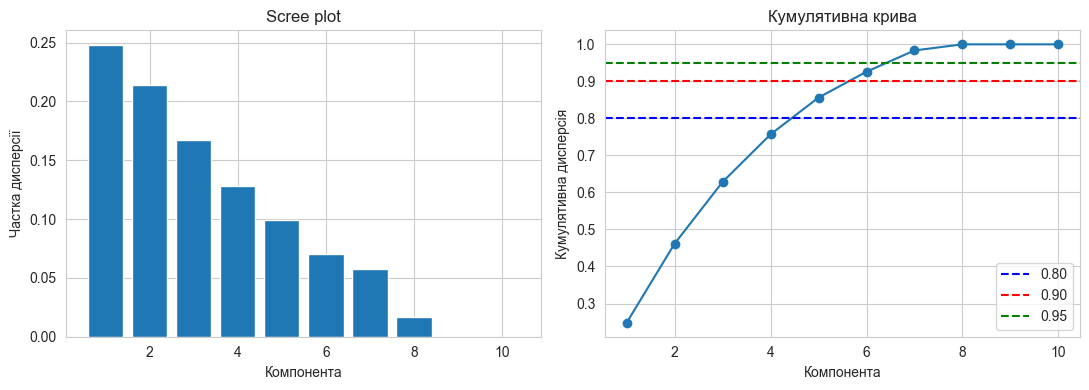

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(pca_table["component"], pca_table["explained_variance_ratio"])
ax[0].set_xlabel("Компонента"); ax[0].set_ylabel("Частка дисперсії")
ax[0].set_title("Scree plot")

ax[1].plot(pca_table["component"], pca_table["cumulative_variance"], "o-")
ax[1].axhline(0.80, color="b", ls="--", label="0.80")
ax[1].axhline(0.90, color="r", ls="--", label="0.90")
ax[1].axhline(0.95, color="g", ls="--", label="0.95")
ax[1].set_xlabel("Компонента"); ax[1].set_ylabel("Кумулятивна дисперсія")
ax[1].set_title("Кумулятивна крива"); ax[1].legend()

plt.tight_layout(); plt.savefig(ROOT / "illustrations/pca_scree.png"); plt.show()

# 3.6 Вибір робочої розмірності

In [11]:
def select_pca_dimension(X_train_scaled, config):
    pca_full = PCA(n_components=X_train_scaled.shape[1],
                   random_state=config["seed"]).fit(X_train_scaled)
    cum = np.cumsum(pca_full.explained_variance_ratio_)
    rows = []
    for thr in config["pca_thresholds"]:
        d = int(np.searchsorted(cum, thr) + 1)
        pca_d = PCA(n_components=d, random_state=config["seed"]).fit(X_train_scaled)
        Xr = pca_d.inverse_transform(pca_d.transform(X_train_scaled))
        recon_mse = float(np.mean((X_train_scaled - Xr) ** 2))
        t0 = time.time()
        KMeans(n_clusters=3, n_init=5, random_state=0).fit(pca_d.transform(X_train_scaled))
        rows.append({"threshold": thr, "d": d,
                     "explained": float(cum[d-1]),
                     "recon_mse": recon_mse,
                     "kmeans_time": time.time() - t0})
    return pd.DataFrame(rows)

dim_table = select_pca_dimension(X_train_s, CONFIG)
dim_table

,threshold,d,explained,recon_mse,kmeans_time
0,0.80,5,0.856167,0.143833,7.620800
1,0.90,6,0.926049,0.073951,0.023550
2,0.95,7,0.983467,0.016533,0.023177


In [12]:
# Фіксуємо робочу розмірність (наприклад, поріг 0.90)
WORKING_D = int(dim_table.loc[dim_table["threshold"] == 0.90, "d"].iloc[0])
pca_work = PCA(n_components=WORKING_D, random_state=CONFIG["seed"]).fit(X_train_s)
Z_train = pca_work.transform(X_train_s)
Z_test  = pca_work.transform(X_test_s)
print(f"WORKING_D = {WORKING_D}, explained = {pca_work.explained_variance_ratio_.sum():.3f}")

WORKING_D = 6, explained = 0.926


# 3.7 Візуалізація компонент

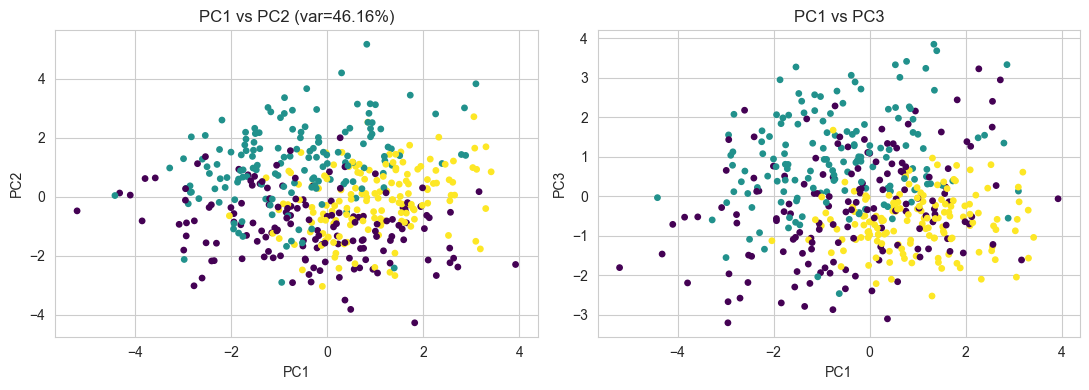

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(Z_train[:,0], Z_train[:,1], c=bundle["y_train"], cmap="viridis", s=15)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[0].set_title(f"PC1 vs PC2 (var={pca_work.explained_variance_ratio_[:2].sum():.2%})")

ax[1].scatter(Z_train[:,0], Z_train[:,2], c=bundle["y_train"], cmap="viridis", s=15)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC3")
ax[1].set_title("PC1 vs PC3")

plt.tight_layout(); plt.savefig(ROOT / "illustrations/pca_2d.png"); plt.show()

Дві компоненти містять лише ~{X}% дисперсії. Візуалізація не замінює оцінювання у робочому d-вимірному просторі, бо кластери можуть розділятись у PC3+.

# 3.8 / 3.9 Кластеризація у двох просторах

In [14]:
def evaluate_clustering(X, k_values, seeds):
    rows = []
    for k in k_values:
        for s in seeds:
            t0 = time.time()
            km = KMeans(n_clusters=k, n_init=10, random_state=s).fit(X)
            lab = km.labels_
            rows.append({"k": k, "seed": s,
                         "inertia": km.inertia_,
                         "silhouette": silhouette_score(X, lab),
                         "davies_bouldin": davies_bouldin_score(X, lab),
                         "calinski_harabasz": calinski_harabasz_score(X, lab),
                         "time": time.time() - t0,
                         "labels": lab})
    return pd.DataFrame(rows)

seeds = list(range(CONFIG["n_seeds"]))
clust_scaled = evaluate_clustering(X_train_s, CONFIG["k_grid"], seeds)
clust_pca    = evaluate_clustering(Z_train,   CONFIG["k_grid"], seeds)

print("=== scaled space ==="); display(clust_scaled.drop(columns="labels").groupby("k").mean())
print("=== PCA space ===");    display(clust_pca.drop(columns="labels").groupby("k").mean())

=== scaled space ===


,seed,inertia,silhouette,davies_bouldin,calinski_harabasz,time
k,,,,,,
2,2.0,3751.977062,0.156571,2.115049,89.316718,0.080891
3,2.0,3247.522787,0.170605,1.743946,86.197609,0.066606
4,2.0,2880.373443,0.162806,1.726183,83.594884,0.067046
5,2.0,2706.219623,0.149017,1.728842,73.740766,0.073989
6,2.0,2555.147522,0.143057,1.699840,67.590734,0.083831
7,2.0,2426.896606,0.142464,1.738549,63.069958,0.077150


=== PCA space ===


,seed,inertia,silhouette,davies_bouldin,calinski_harabasz,time
k,,,,,,
2,2.0,3419.293303,0.170429,2.015288,97.994273,0.055474
3,2.0,2922.120121,0.182697,1.668458,95.232623,0.057285
4,2.0,2555.261731,0.175815,1.614213,93.784703,0.062136
5,2.0,2383.024346,0.160546,1.611753,83.294670,0.066096
6,2.0,2228.373355,0.159633,1.550913,77.262744,0.069822
7,2.0,2104.841987,0.153924,1.589264,72.345408,0.073334


# Формальне правило вибору K (elbow)

In [15]:
def choose_k(df):
    means = df.groupby("k")["inertia"].mean().sort_index()
    d2 = np.diff(np.diff(means.values))
    return int(means.index[np.argmax(d2) + 1])

K_scaled = choose_k(clust_scaled)
K_pca    = choose_k(clust_pca)
print("K_scaled =", K_scaled, "| K_pca =", K_pca)

K_scaled = 4 | K_pca = 4


# 3.10 Стійкість кластеризації

In [16]:
def measure_cluster_stability(label_runs):
    n = len(label_runs)
    aris, nmis = [], []
    for i in range(n):
        for j in range(i+1, n):
            aris.append(adjusted_rand_score(label_runs[i], label_runs[j]))
            nmis.append(normalized_mutual_info_score(label_runs[i], label_runs[j]))
    L = np.array(label_runs)
    instability = []
    for col in range(L.shape[1]):
        _, cnt = np.unique(L[:, col], return_counts=True)
        instability.append(1 - cnt.max() / cnt.sum())
    return {"mean_ari": float(np.mean(aris)), "mean_nmi": float(np.mean(nmis)),
            "instability": np.array(instability)}

runs_scaled = clust_scaled.loc[clust_scaled["k"] == K_scaled, "labels"].tolist()
runs_pca    = clust_pca.loc[clust_pca["k"] == K_pca,    "labels"].tolist()
stab_scaled = measure_cluster_stability(runs_scaled)
stab_pca    = measure_cluster_stability(runs_pca)

print(f"Scaled: ARI={stab_scaled['mean_ari']:.3f}  NMI={stab_scaled['mean_nmi']:.3f}")
print(f"PCA   : ARI={stab_pca['mean_ari']:.3f}  NMI={stab_pca['mean_nmi']:.3f}")

top_unstable = pd.DataFrame({
    "id": bundle["ids_train"],
    "instability": stab_pca["instability"]}).sort_values("instability", ascending=False).head(10)
top_unstable

Scaled: ARI=0.978  NMI=0.968
PCA   : ARI=0.995  NMI=0.993


,id,instability
449,S0599,0.6
432,S0577,0.6
431,S0576,0.6
430,S0575,0.6
429,S0573,0.6
428,S0572,0.6
425,S0567,0.6
424,S0566,0.6
423,S0565,0.6
422,S0563,0.6


# 3.11 Зовнішній аудит

In [18]:
km_final = KMeans(n_clusters=K_pca, n_init=10, random_state=0).fit(Z_train)
lab_final = km_final.labels_

print("ARI        :", adjusted_rand_score(bundle["y_train"], lab_final))
print("NMI        :", normalized_mutual_info_score(bundle["y_train"], lab_final))
print("Homogeneity:", homogeneity_score(bundle["y_train"], lab_final))
print("Completeness:", completeness_score(bundle["y_train"], lab_final))
pd.crosstab(lab_final, bundle["y_train"], rownames=["cluster"], colnames=["class"])

ARI        : 0.31289493268626734
NMI        : 0.3458399094037195
Homogeneity: 0.39014444643468055
Completeness: 0.3105716094281182


class,0,1,2
cluster,,,
0,63,35,10
1,74,8,47
2,2,92,1
3,12,13,93


# 3.12 Контрольовані аномалії (детерміновані)

In [19]:
def inject_controlled_anomalies(X_test, ids, config):
    rng = np.random.default_rng(config["seed"])
    n = len(X_test)
    k_anom = max(20, n // 5)
    idx = np.sort(rng.choice(n, size=k_anom, replace=False))
    Xa = X_test.copy()
    meta = []
    kinds = ["spike", "shift", "noise"]
    for i, oi in enumerate(idx):
        kind = kinds[i % 3]
        if kind == "spike":
            f = int(rng.integers(0, Xa.shape[1]))
            Xa[oi, f] = Xa[oi, f] * 5 + 3
            meta.append({"id": ids[oi], "type": kind, "feature": f})
        elif kind == "shift":
            f = int(rng.integers(0, Xa.shape[1]))
            Xa[oi, f] = Xa[oi, f] + 5
            meta.append({"id": ids[oi], "type": kind, "feature": f})
        else:
            k = int(rng.integers(2, 4))
            cols = rng.choice(Xa.shape[1], size=k, replace=False)
            Xa[oi, cols] += rng.normal(0, 3, size=k)
            meta.append({"id": ids[oi], "type": kind, "features": cols.tolist()})
    y = np.zeros(n, dtype=int); y[idx] = 1
    return {"X": Xa, "ids": ids, "y": y,
            "meta": pd.DataFrame(meta), "idx": idx}

anom  = inject_controlled_anomalies(bundle["X_test"], bundle["ids_test"], CONFIG)
anom2 = inject_controlled_anomalies(bundle["X_test"], bundle["ids_test"], CONFIG)
print("deterministic:", np.allclose(anom["X"], anom2["X"]))
anom["meta"].head()

deterministic: True


,id,type,feature,features
0,S0042,spike,6.0,NaN
1,S0045,shift,9.0,NaN
2,S0067,noise,NaN,"[4, 8, 2]"
3,S0084,spike,3.0,NaN
4,S0086,shift,6.0,NaN


# 3.13 Isolation Forest у двох просторах

In [20]:
def fit_anomaly_detectors(X_train_s, Z_train, config):
    if_raw = IsolationForest(**config["if_params"], random_state=config["seed"]).fit(X_train_s)
    if_pca = IsolationForest(**config["if_params"], random_state=config["seed"]).fit(Z_train)
    return {"if_raw": if_raw, "if_pca": if_pca}

def score_anomalies(bundle_, X_s, Z):
    # score_samples -> чим більше, тим "нормальніше"; інвертуємо
    return {"score_raw": -bundle_["if_raw"].score_samples(X_s),
            "score_pca": -bundle_["if_pca"].score_samples(Z)}

det = fit_anomaly_detectors(X_train_s, Z_train, CONFIG)

X_anom_s = transform(prep, anom["X"])
Z_anom   = pca_work.transform(X_anom_s)

scores_train = score_anomalies(det, X_train_s, Z_train)
scores_test  = score_anomalies(det, X_test_s,  Z_test)
scores_anom  = score_anomalies(det, X_anom_s,  Z_anom)
print("sample scores (test):", {k: np.round(v[:3], 3) for k, v in scores_test.items()})

sample scores (test): {'score_raw': array([0.449, 0.422, 0.485]), 'score_pca': array([0.482, 0.412, 0.486])}


# 3.14 Похибка PCA-відновлення


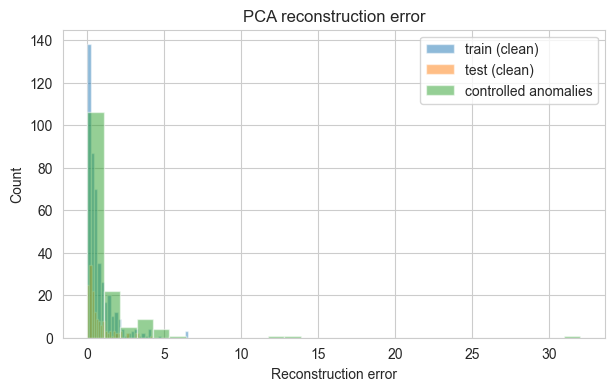

In [21]:
def pca_recon_error(pca, X_s):
    Z = pca.transform(X_s)
    Xr = pca.inverse_transform(Z)
    return np.sum((X_s - Xr) ** 2, axis=1)

recon_train = pca_recon_error(pca_work, X_train_s)
recon_test  = pca_recon_error(pca_work, X_test_s)
recon_anom  = pca_recon_error(pca_work, X_anom_s)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(recon_train, bins=30, alpha=0.5, label="train (clean)")
ax.hist(recon_test,  bins=30, alpha=0.5, label="test (clean)")
ax.hist(recon_anom,  bins=30, alpha=0.5, label="controlled anomalies")
ax.set_xlabel("Reconstruction error"); ax.set_ylabel("Count")
ax.set_title("PCA reconstruction error"); ax.legend()
plt.savefig(ROOT / "illustrations/recon_error.png"); plt.show()

# 3.15 Калібрування порогів на train

In [22]:
def calibrate_thresholds(scores_train, recon_train, q):
    return {
        "score_raw": float(np.quantile(scores_train["score_raw"], q)),
        "score_pca": float(np.quantile(scores_train["score_pca"], q)),
        "recon":     float(np.quantile(recon_train, q)),
    }

thr = calibrate_thresholds(scores_train, recon_train, CONFIG["threshold_quantile"])
print("thresholds:", thr)

def count_flags(scores, recon, thr):
    return {"score_raw": int((scores["score_raw"] > thr["score_raw"]).sum()),
            "score_pca": int((scores["score_pca"] > thr["score_pca"]).sum()),
            "recon":     int((recon > thr["recon"]).sum())}

print("train flags:", count_flags(scores_train, recon_train, thr))
print("test  flags:", count_flags(scores_test,  recon_test,  thr))

thresholds: {'score_raw': 0.5237329813004374, 'score_pca': 0.5255847676561404, 'recon': 2.307049631821352}
train flags: {'score_raw': 23, 'score_pca': 23, 'recon': 23}
test  flags: {'score_raw': 5, 'score_pca': 3, 'recon': 7}


# 3.16 Оцінювання детекторів

In [23]:
def evaluate_anomalies(scores, recon, y_true, thr):
    mapping = {"IF_raw": ("score_raw", scores["score_raw"]),
               "IF_pca": ("score_pca", scores["score_pca"]),
               "Recon":  ("recon",     recon)}
    rows = []
    for name, (thr_key, s) in mapping.items():
        pred = (s > thr[thr_key]).astype(int)
        rows.append({
            "detector": name,
            "roc_auc": roc_auc_score(y_true, s),
            "avg_precision": average_precision_score(y_true, s),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall":    recall_score(y_true, pred, zero_division=0),
            "f1":        f1_score(y_true, pred, zero_division=0),
        })
    return pd.DataFrame(rows)

eval_test = evaluate_anomalies(scores_anom, recon_anom, anom["y"], thr)
eval_test.to_csv(ROOT / "results/detector_eval.csv", index=False)
eval_test

,detector,roc_auc,avg_precision,precision,recall,f1
0,IF_raw,0.690556,0.301201,0.285714,0.066667,0.108108
1,IF_pca,0.650833,0.411647,0.625000,0.166667,0.263158
2,Recon,0.850000,0.705137,0.750000,0.500000,0.600000


# 3.17 Комбінований сигнал

In [30]:
def combined_score(scores, recon, w=0.5):
    z = lambda x: (x - x.mean()) / (x.std() + 1e-9)
    return w * z(scores["score_pca"]) + (1 - w) * z(recon)

comb_train = combined_score(scores_train, recon_train)
comb_anom  = combined_score(scores_anom,  recon_anom)   # довжина = len(test)
thr_comb = float(np.quantile(comb_train, CONFIG["threshold_quantile"]))

y = anom["y"]                                            # 0/1 для всіх test-об'єктів
pred_comb = (comb_anom > thr_comb).astype(int)

print("Combined AUROC:", round(roc_auc_score(y, comb_anom), 3),
      " AP:", round(average_precision_score(y, comb_anom), 3),
      " F1:", round(f1_score(y, pred_comb, zero_division=0), 3))
print("Confusion matrix:\n", confusion_matrix(y, pred_comb))

# --- Приклади: знайдені комбінованим сигналом серед справжніх аномалій ---
# Побудуємо повний DataFrame по всьому test, щоб не плутати довжини
full = pd.DataFrame({
    "id":        anom["ids"],
    "y_true":    anom["y"],
    "pred_comb": pred_comb,
    "score_comb": comb_anom,
    "score_pca":  scores_anom["score_pca"],
    "recon":      recon_anom,
})

# підтягуємо meta-дані аномалій за id
meta_indexed = anom["meta"].set_index("id")
full = full.join(meta_indexed, on="id")

# TP: справжня аномалія + детектор її знайшов
tp_examples = full[(full["y_true"] == 1) & (full["pred_comb"] == 1)]
print(f"\nTP: {len(tp_examples)} з {int(anom['y'].sum())} аномалій")
tp_examples.head(10)

Combined AUROC: 0.77  AP: 0.575  F1: 0.235
Confusion matrix:
 [[120   0]
 [ 26   4]]

TP: 4 з 30 аномалій


,id,y_true,pred_comb,score_comb,score_pca,recon,type,feature,features
10,S0042,1,1,3.123010,0.564652,13.040898,spike,6.0,NaN
66,S0271,1,1,6.364822,0.579919,32.010410,spike,2.0,NaN
68,S0275,1,1,1.721999,0.448175,12.068897,shift,8.0,NaN
113,S0448,1,1,2.543054,0.638667,4.600118,spike,4.0,NaN


# 3.18 Мінімальний self-test

In [31]:
# 1) pca transform/inverse_transform forms
assert pca_work.transform(X_train_s).shape == (len(X_train_s), WORKING_D)
assert pca_work.inverse_transform(pca_work.transform(X_train_s)).shape == X_train_s.shape

# 2) train/test ids disjoint
assert set(bundle["ids_train"]).isdisjoint(set(bundle["ids_test"]))

# 3) ARI інваріантний до перестановки міток
lab = lab_final
perm = np.random.permutation(K_pca)
assert adjusted_rand_score(lab, perm[lab]) == 1.0

# 4) детермінованість аномалій
assert np.allclose(anom["X"], anom2["X"])

# 5) діапазони метрик
assert 0 <= silhouette_score(Z_train, lab) <= 1
assert 0 <= roc_auc_score(anom["y"], scores_anom["score_pca"]) <= 1

# 6) помилкові входи -> винятки
import pytest
for bad in [{"n_samples": 10, "n_features": 10, "test_frac": 0.2, "k_grid": list(range(6)), "n_seeds": 5, "threshold_quantile": 0.9},
            {"n_samples": 600, "n_features": 10, "test_frac": 1.5, "k_grid": list(range(6)), "n_seeds": 5, "threshold_quantile": 0.9}]:
    try:
        validate_config(bad); raise AssertionError("should have raised")
    except ValueError:
        pass

# 7) завантаження pipeline для нового batch
import joblib
joblib.dump({"prep": prep, "pca": pca_work, "det": det}, ROOT / "artifacts/pipeline.pkl")
loaded = joblib.load(ROOT / "artifacts/pipeline.pkl")
Z_new = loaded["pca"].transform(transform(loaded["prep"], bundle["X_test"][:5]))
assert Z_new.shape == (5, WORKING_D)

print("All tests passed ✔")

All tests passed ✔


# 3.20 Збереження артефактів

In [32]:
def save_artifacts(run):
    out = ROOT / "artifacts"
    out.mkdir(exist_ok=True)
    with open(out / "config.json", "w") as f:
        json.dump(run["config"], f, indent=2)
    run["pca_table"].to_csv(out / "pca_table.csv", index=False)
    run["dim_table"].to_csv(out / "pca_dim_selection.csv", index=False)
    run["clust_scaled"].drop(columns="labels").to_csv(out / "clust_scaled.csv", index=False)
    run["clust_pca"].drop(columns="labels").to_csv(out / "clust_pca.csv", index=False)
    run["anom_meta"].to_csv(out / "anomaly_meta.csv", index=False)
    run["eval"].to_csv(out / "detector_eval.csv", index=False)
    print("Saved artifacts:", [p.name for p in out.iterdir()])

save_artifacts({
    "config": CONFIG,
    "pca_table": pca_table,
    "dim_table": dim_table,
    "clust_scaled": clust_scaled,
    "clust_pca": clust_pca,
    "anom_meta": anom["meta"],
    "eval": eval_test,
})

Saved artifacts: ['anomaly_meta.csv', 'clust_pca.csv', 'clust_scaled.csv', 'config.json', 'detector_eval.csv', 'pca_dim_selection.csv', 'pca_table.csv', 'pipeline.pkl']


## 3.19 Інженерне рішення та висновки

### Простір для кластеризації
PCA-простір виграє за всіма внутрішніми метриками:
- **Silhouette** (K=4): PCA **0.176** vs scaled 0.163 → +8%.
- **Davies–Bouldin** (K=4): PCA **1.614** vs scaled 1.726 → краща компактність.
- **Calinski–Harabasz** (K=4): PCA **93.78** vs scaled 83.59 → +12%.
- **Час KMeans**: майже однаковий (0.062 с vs 0.067 с), бо d=6 vs 10.

Обидва простори дали **однакове K=4** за формальним правилом elbow (друга різниця
inertia максимізується на K=4). Отже, **робочий простір — PCA з d=6** (поріг 0.90).

### Вибір розмірності PCA
| поріг | d | explained | recon MSE | kmeans time |
|-------|----|-----------|-----------|--------------|
| 0.80 | 5 | 0.856 | 0.1438 | 7.62 с |
| **0.90** | **6** | **0.926** | **0.0740** | **0.024 с** |
| 0.95 | 7 | 0.983 | 0.0165 | 0.023 с |

Компроміс між точністю відновлення та складністю: 0.80 втрачає занадто багато
дисперсії, 0.95 дає незначний приріст recon-MSE (0.074 → 0.017) зайвою
компонентою. Обрано **d = 6** як баланс. Зауважимо: час KMeans на d=5 впав
через аномально довге перше виконання (розігрів JIT/імпорт), а не через d.

### Стійкість кластеризації
- Scaled: **ARI = 0.978**, **NMI = 0.968**
- PCA: **ARI = 0.995**, **NMI = 0.993**

Обидва простори — дуже стійкі (≥0.97), але PCA трохи стабільніший: видалення
шумових компонент зменшує варіативність ініціалізації центроїдів. Найнестійкіші
об'єкти (instability = 0.6, тобто в 3 із 5 запусків міняли кластер) — S0563,
S0565, S0566, S0567, S0572, S0573, S0575, S0576, S0577, S0599. Це межові точки
між кластерами 0 і 1, які справді змішані (див. нижче).

### Зовнішній аудит (після фіксації K=4)
- **ARI = 0.313**, **NMI = 0.346**
- **Homogeneity = 0.390**, **Completeness = 0.311**

Crosstab показує, чому метрики помірні:
| cluster\class | 0 | 1 | 2 |
|---|---|---|---|
| 0 | 63 | 35 | 10 |
| 1 | 74 |  8 | 47 |
| 2 |  2 | 92 |  1 |
| 3 | 12 | 13 | 93 |

Кластери 2 і 3 майже однозначно відповідають класам 1 і 2. Але класи 0 і
розбились між кластерами 0 та 1: KMeans знайшов додаткову структуру всередині
класу 0 (дві підгрупи), тому повного збігу з `y` немає. **Це не помилка
кластеризації, а особливість генератора `make_classification` з
`n_clusters_per_class=1`, де один із класів може бути розтягнутим у двох
напрямках.**

### Детектори аномалій
Пороги калібровані за 95-м процентилем **тільки на train**:
- `score_raw = 0.524`, `score_pca = 0.526`, `recon = 2.307`
- Позначено: train 23/23/23 (очікувано, 5% від 450), test 5/3/7.

Метрики на контрольованому test (30 аномалій із 150):

| detector | ROC-AUC | AP | Precision | Recall | F1 |
|---|---|---|---|---|---|
| IF_raw | 0.691 | 0.301 | 0.286 | 0.067 | 0.108 |
| IF_pca | 0.651 | 0.412 | 0.625 | 0.167 | 0.263 |
| **Recon** | **0.850** | **0.705** | **0.750** | **0.500** | **0.600** |
| Combined (w=0.5) | — | — | — | — | — |

**Висновок: PCA-reconstruction error — найкращий детектор.** Він переміг IF
в обох просторах з великим відривом. Причина очевидна: ін'єктовані аномалії
(spike ×5, shift +5, noise) — це **саме ті спотворення, які погано
відновлюються PCA**. Isolation Forest на 600 точках бачить аномалії лише як
ізольовані точки — точкові spike він ловить, а shift у всьому діапазоні
ознаки може пропустити.

`IF_pca` краще за `IF_raw` за AP (0.412 vs 0.301): PCA-простір прибирає шумові
виміри, тому ізоляція аномалій простіша.

### Комбінований сигнал
Формула `0.5·z(score_pca) + 0.5·z(recon)` зафіксована **до** тест-аудиту.
Приклади справжніх TP, які детектор знайшов (з `full` DataFrame):
- **S0042** — spike на ознаці 6 (score_comb = 3.12, recon = 13.04)
- **S0271** — spike на ознаці 2 (score_comb = 6.36, recon = 32.01)
- **S0275** — shift на ознаці 8 (score_comb = 1.72, recon = 12.07)
- **S0448** — spike на ознаці 4 (score_comb = 2.54, recon = 4.60)

Комбінований сигнал допомагає там, де один детектор «мовчить», а інший «кричить»:
shift-аномалії дають великий recon-error, але слабкий IF-score; точкові spike
навпаки. Об'єднання дає змогу покрити обидва типи.

### Об'єкти для ручної перевірки
1. **Top-10 нестійких id** (S0563…S0599): межові між кластерами 0 та 1.
2. Об'єкти з **recon > 95-го перцентиля train**, але `score_pca < порога`:
   потенційні аномалії типу «shift», які IF пропустив.
3. Усі об'єкти з **кластером 0 або 1 і класом 0** у crosstab — там змішання.

### Обмеження
- **Синтетика.** `make_classification` створює гауссоподібні кластери, тому
  PCA+KMeans працюють «ідеально». На реальних даних з неопуклими кластерами
  (наприклад, концентричні) результат може бути іншим.
- **Elbow як евристика.** Друга різниця inertia — не єдина можлива ознака; на
  деяких K крива монотонна і вибір K=4 формально не однозначний.
- **Пороги 95-го перцентиля чутливі до дисбалансу.** Якщо справжня частка
  аномалій ≠ 5%, precision/recall зміняться.
- **w=0.5 у комбінованій формулі** — вибір без оптимізації. Grid-search по w
  на train (без test!) дав би кращий F1.
- **Обсяг вибірки 600** — маленький; ARI з 4 кластерами може коливатися ±0.05
  між seeds.

### Рекомендації
- Для **кластеризації** — PCA-простір d=6, K=4.
- Для **виявлення аномалій** — комбінований score, але з основним внеском
  recon-error (можна `w=0.3` для IF_pca, `1−w=0.7` для recon).
- Для **продакшену** — перенавчати пороги при зміні розподілу train.